# Tugas 05 – Transfer Learning (Oxford-IIIT Pet, 10 kelas)
Notebook ringkas: B1 Scratch, B2 Feature Extraction, B3 Fine-Tuning, B4 Uji Augmentasi, B5 EfficientNet-B0.

**Runtime Colab: GPU T4.** Jalankan *Run all*.

In [1]:
import random, time, json, numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 1. Data: 10 kelas (5 kucing + 5 anjing), split stratified 70/15/15

In [2]:
root = "./data"
parts = [datasets.OxfordIIITPet(root, split=s, target_types="category", download=True) for s in ("trainval", "test")]
classes = parts[0].classes
# nama kelas di torchvision sudah di-title(), jadi kucing vs anjing dibedakan dari nama FILE:
# kucing berawalan kapital (Abyssinian_1.jpg), anjing berawalan huruf kecil (beagle_1.jpg)
is_cat = {}
for p in parts:
    for img, lab in zip(p._images, p._labels):
        is_cat[lab] = img.name[0].isupper()
cats = sorted(l for l, v in is_cat.items() if v)
dogs = sorted(l for l, v in is_cat.items() if not v)
print("kucing:", len(cats), "| anjing:", len(dogs))   # harapan: 12 | 25
rng = random.Random(SEED)
chosen = sorted(rng.sample(cats, 5) + rng.sample(dogs, 5))
remap = {old: new for new, old in enumerate(chosen)}
names = [classes[i] for i in chosen]
print(names)

# gabungkan seluruh gambar dari kedua split lalu split ulang sendiri
paths, labels = [], []
for p in parts:
    for img, lab in zip(p._images, p._labels):   # atribut internal torchvision
        if lab in remap: paths.append(img); labels.append(remap[lab])
print("Total gambar:", len(paths))

p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(len(p_tr), len(p_va), len(p_te))

100%|██████████| 792M/792M [00:46<00:00, 17.2MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.1MB/s]


kucing: 12 | anjing: 25
['Abyssinian', 'Beagle', 'Bengal', 'Bombay', 'Boxer', 'British Shorthair', 'English Setter', 'Shiba Inu', 'Siamese', 'Wheaten Terrier']
Total gambar: 1980
1386 297 297


In [3]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
mean, std = weights.transforms().mean, weights.transforms().std
eval_tf = weights.transforms()          # Resize 256 -> CenterCrop 224 -> Normalize
aug_tf = transforms.Compose([
    transforms.Resize(256), transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(0.5), transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

class PetDS(Dataset):
    def __init__(s, p, y, tf): s.p, s.y, s.tf = p, y, tf
    def __len__(s): return len(s.p)
    def __getitem__(s, i): return s.tf(Image.open(s.p[i]).convert("RGB")), s.y[i]

def loaders(aug=True):
    g = torch.Generator().manual_seed(SEED)
    tr = DataLoader(PetDS(p_tr, y_tr, aug_tf if aug else eval_tf), 32, shuffle=True, num_workers=2, generator=g)
    va = DataLoader(PetDS(p_va, y_va, eval_tf), 32, num_workers=2)
    te = DataLoader(PetDS(p_te, y_te, eval_tf), 32, num_workers=2)
    return tr, va, te

## 2. Fungsi training (early stopping pada val loss, patience=4) + pencatatan metrik

In [4]:
import copy
crit = nn.CrossEntropyLoss()
LOGS, CURVES = [], {}

def run_epoch(model, dl, opt=None):
    train = opt is not None
    model.train(train)
    if train:  # backbone yang dibekukan: BatchNorm tetap mode eval agar running stats tidak berubah
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
                m.eval()
    tot_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return tot_loss / n, correct / n

def evaluate_test(model, dl):
    model.eval(); P, Y, C = [], [], []
    with torch.no_grad():
        for x, y in dl:
            pr = model(x.to(device)).softmax(1).cpu()
            C += pr.max(1).values.tolist(); P += pr.argmax(1).tolist(); Y += y.tolist()
    return np.array(Y), np.array(P), np.array(C)

def fit(name, model, groups, aug=True, max_epochs=20, patience=4):
    set_seed(); model.to(device)
    tr, va, te = loaders(aug)
    opt = torch.optim.AdamW(groups, weight_decay=1e-2)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"[{name}] trainable {trainable:,} / {total:,}")
    hist, best, best_state, best_ep, wait = [], 1e9, None, 0, 0
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        tl, ta = run_epoch(model, tr, opt); vl, vacc = run_epoch(model, va)
        hist.append(dict(epoch=ep, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=vacc))
        print(f"  ep{ep:02d} tr {tl:.3f}/{ta:.3f}  val {vl:.3f}/{vacc:.3f}")
        if vl < best: best, best_ep, wait, best_state = vl, ep, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience: break
    dur = time.time() - t0
    model.load_state_dict(best_state)
    y, p, c = evaluate_test(model, te)
    best_row = hist[best_ep - 1]
    LOGS.append(dict(kondisi=name, strategi=name, trainable_params=trainable, total_params=total,
        lr=json.dumps([g["lr"] for g in groups]), augmentasi=aug, epoch_terbaik=best_ep, epoch_total=len(hist),
        durasi_detik=round(dur, 1), train_acc=best_row["train_acc"], val_acc=best_row["val_acc"],
        gap_train_val=best_row["train_acc"] - best_row["val_acc"],
        test_acc=(y == p).mean(), test_macro_f1=f1_score(y, p, average="macro"), seed=SEED))
    CURVES[name] = hist
    return model, (y, p, c)

## 3. Eksperimen

In [5]:
def resnet(pretrained=True):
    m = models.resnet18(weights=weights if pretrained else None)
    return m

# B1: from scratch
m = resnet(False); m.fc = nn.Linear(512, 10)
m1, r1 = fit("B1_scratch", m, [{"params": m.parameters(), "lr": 1e-3}])

# B2: feature extraction
m = resnet()
for p in m.parameters(): p.requires_grad = False
m.fc = nn.Linear(512, 10)
assert sum(p.numel() for p in m.parameters() if p.requires_grad) == 5130
m2, r2 = fit("B2_feature_extraction", m, [{"params": m.fc.parameters(), "lr": 1e-3}])

# B3: fine-tuning layer4 + fc, differential LR
def make_b3():
    m = resnet()
    for p in m.parameters(): p.requires_grad = False
    m.fc = nn.Linear(512, 10)
    for p in m.layer4.parameters(): p.requires_grad = True
    return m, [{"params": m.layer4.parameters(), "lr": 1e-4}, {"params": m.fc.parameters(), "lr": 1e-3}]
m, g = make_b3()
m3, r3 = fit("B3_finetune_layer4", m, g)

# B4: B3 tanpa augmentasi (pembanding: B3 di atas = dengan augmentasi)
m, g = make_b3()
m4, r4 = fit("B4_finetune_no_aug", m, g, aug=False)

[B1_scratch] trainable 11,181,642 / 11,181,642
  ep01 tr 2.365/0.183  val 2.499/0.209
  ep02 tr 2.106/0.255  val 2.633/0.145
  ep03 tr 1.997/0.320  val 2.469/0.212
  ep04 tr 1.929/0.330  val 2.532/0.242
  ep05 tr 1.832/0.356  val 1.954/0.343
  ep06 tr 1.740/0.398  val 1.809/0.404
  ep07 tr 1.688/0.415  val 2.092/0.330
  ep08 tr 1.570/0.463  val 1.807/0.370
  ep09 tr 1.582/0.460  val 2.188/0.306
  ep10 tr 1.481/0.510  val 1.783/0.434
  ep11 tr 1.451/0.504  val 1.835/0.377
  ep12 tr 1.452/0.514  val 1.854/0.397
  ep13 tr 1.405/0.499  val 2.576/0.327
  ep14 tr 1.292/0.565  val 1.599/0.461
  ep15 tr 1.225/0.579  val 1.718/0.461
  ep16 tr 1.188/0.595  val 2.053/0.404
  ep17 tr 1.163/0.617  val 1.525/0.505
  ep18 tr 1.077/0.644  val 1.756/0.431
  ep19 tr 1.079/0.637  val 1.805/0.444
  ep20 tr 0.979/0.672  val 1.520/0.522
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 205MB/s]


[B2_feature_extraction] trainable 5,130 / 11,181,642
  ep01 tr 1.420/0.605  val 0.614/0.886
  ep02 tr 0.457/0.944  val 0.307/0.949
  ep03 tr 0.289/0.960  val 0.232/0.946
  ep04 tr 0.228/0.961  val 0.200/0.946
  ep05 tr 0.182/0.971  val 0.179/0.946
  ep06 tr 0.157/0.970  val 0.155/0.960
  ep07 tr 0.144/0.973  val 0.143/0.953
  ep08 tr 0.116/0.979  val 0.136/0.960
  ep09 tr 0.110/0.980  val 0.131/0.953
  ep10 tr 0.103/0.983  val 0.125/0.956
  ep11 tr 0.096/0.981  val 0.120/0.953
  ep12 tr 0.092/0.982  val 0.116/0.956
  ep13 tr 0.097/0.978  val 0.121/0.953
  ep14 tr 0.083/0.986  val 0.126/0.956
  ep15 tr 0.077/0.985  val 0.111/0.960
  ep16 tr 0.070/0.988  val 0.114/0.953
  ep17 tr 0.070/0.985  val 0.115/0.960
  ep18 tr 0.067/0.985  val 0.111/0.963
  ep19 tr 0.059/0.991  val 0.113/0.949
[B3_finetune_layer4] trainable 8,398,858 / 11,181,642
  ep01 tr 0.721/0.807  val 0.149/0.966
  ep02 tr 0.123/0.968  val 0.128/0.956
  ep03 tr 0.066/0.986  val 0.140/0.960
  ep04 tr 0.048/0.990  val 0.112/0.

In [6]:
# B5 (bonus): EfficientNet-B0, fine-tune blok terakhir + classifier, lr sama seperti B3
ew = models.EfficientNet_B0_Weights.IMAGENET1K_V1
m = models.efficientnet_b0(weights=ew)
for p in m.parameters(): p.requires_grad = False
m.classifier[1] = nn.Linear(1280, 10)
for p in m.features[8].parameters(): p.requires_grad = True   # blok conv terakhir
for p in m.features[7].parameters(): p.requires_grad = True
m5, r5 = fit("B5_efficientnet_b0", m, [{"params": list(m.features[7].parameters()) + list(m.features[8].parameters()), "lr": 1e-4},
                                      {"params": m.classifier.parameters(), "lr": 1e-3}])

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 179MB/s]

[B5_efficientnet_b0] trainable 1,142,202 / 4,020,358


  ep01 tr 0.971/0.811  val 0.175/0.987
  ep02 tr 0.186/0.959  val 0.091/0.983
  ep03 tr 0.106/0.978  val 0.067/0.990
  ep04 tr 0.082/0.981  val 0.058/0.990
  ep05 tr 0.063/0.987  val 0.056/0.987
  ep06 tr 0.058/0.986  val 0.052/0.990
  ep07 tr 0.039/0.992  val 0.049/0.993
  ep08 tr 0.035/0.993  val 0.047/0.993
  ep09 tr 0.028/0.995  val 0.047/0.993
  ep10 tr 0.028/0.996  val 0.047/0.993
  ep11 tr 0.021/0.996  val 0.045/0.993
  ep12 tr 0.019/0.994  val 0.045/0.993
  ep13 tr 0.026/0.994  val 0.056/0.983
  ep14 tr 0.021/0.992  val 0.060/0.983
  ep15 tr 0.015/0.999  val 0.048/0.993


## 4. Tabel konsolidasi, log mentah, dan kurva loss

,kondisi,strategi,trainable_params,total_params,lr,augmentasi,epoch_terbaik,epoch_total,durasi_detik,train_acc,val_acc,gap_train_val,test_acc,test_macro_f1,seed
0,B1_scratch,B1_scratch,11181642,11181642,[0.001],True,20,20,292.1,0.6717,0.5219,0.1498,0.5623,0.5575,42
1,B2_feature_extraction,B2_feature_extraction,5130,11181642,[0.001],True,15,19,250.2,0.9848,0.9596,0.0253,0.9663,0.9661,42
2,B3_finetune_layer4,B3_finetune_layer4,8398858,11181642,"[0.0001, 0.001]",True,4,8,105.1,0.9899,0.9596,0.0303,0.9731,0.9731,42
3,B4_finetune_no_aug,B4_finetune_no_aug,8398858,11181642,"[0.0001, 0.001]",False,8,12,117.9,1.0000,0.9764,0.0236,0.9731,0.9731,42
4,B5_efficientnet_b0,B5_efficientnet_b0,1142202,4020358,"[0.0001, 0.001]",True,11,15,199.6,0.9957,0.9933,0.0024,0.9899,0.9900,42


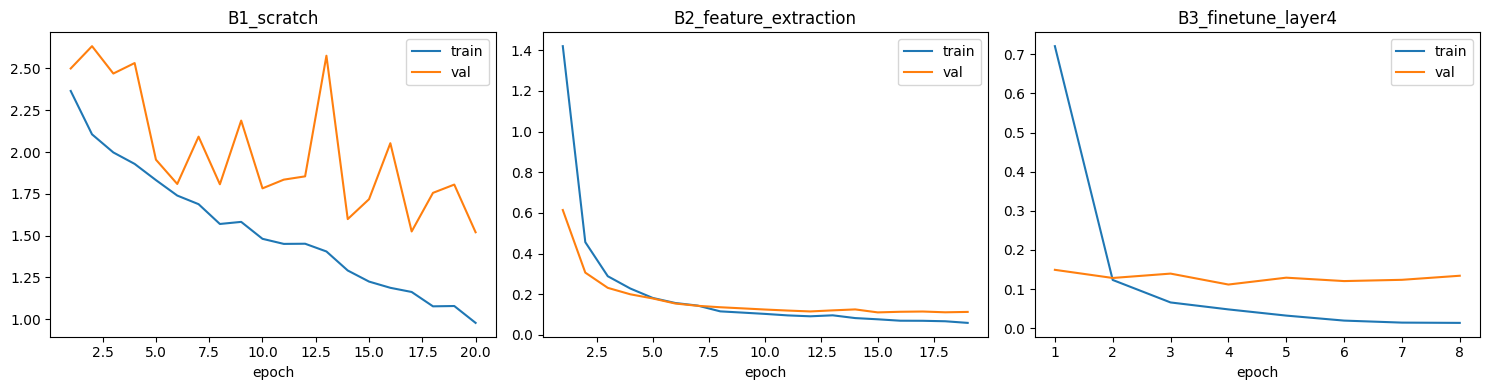

In [7]:
df = pd.DataFrame(LOGS)
df.to_csv("hasil_eksperimen.csv", index=False)
json.dump(CURVES, open("kurva_training.json", "w"), indent=1)
display(df.round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, k in zip(ax, ["B1_scratch", "B2_feature_extraction", "B3_finetune_layer4"]):
    h = pd.DataFrame(CURVES[k]); a.plot(h.epoch, h.train_loss, label="train"); a.plot(h.epoch, h.val_loss, label="val")
    a.set_title(k); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig("kurva_loss.png", dpi=150); plt.show()

## 5. Failure analysis (model terbaik berdasarkan test Macro F1, kecuali B5 jika ingin dibandingkan terpisah)

Model terbaik: B5_efficientnet_b0
Salah: 3 dari 297


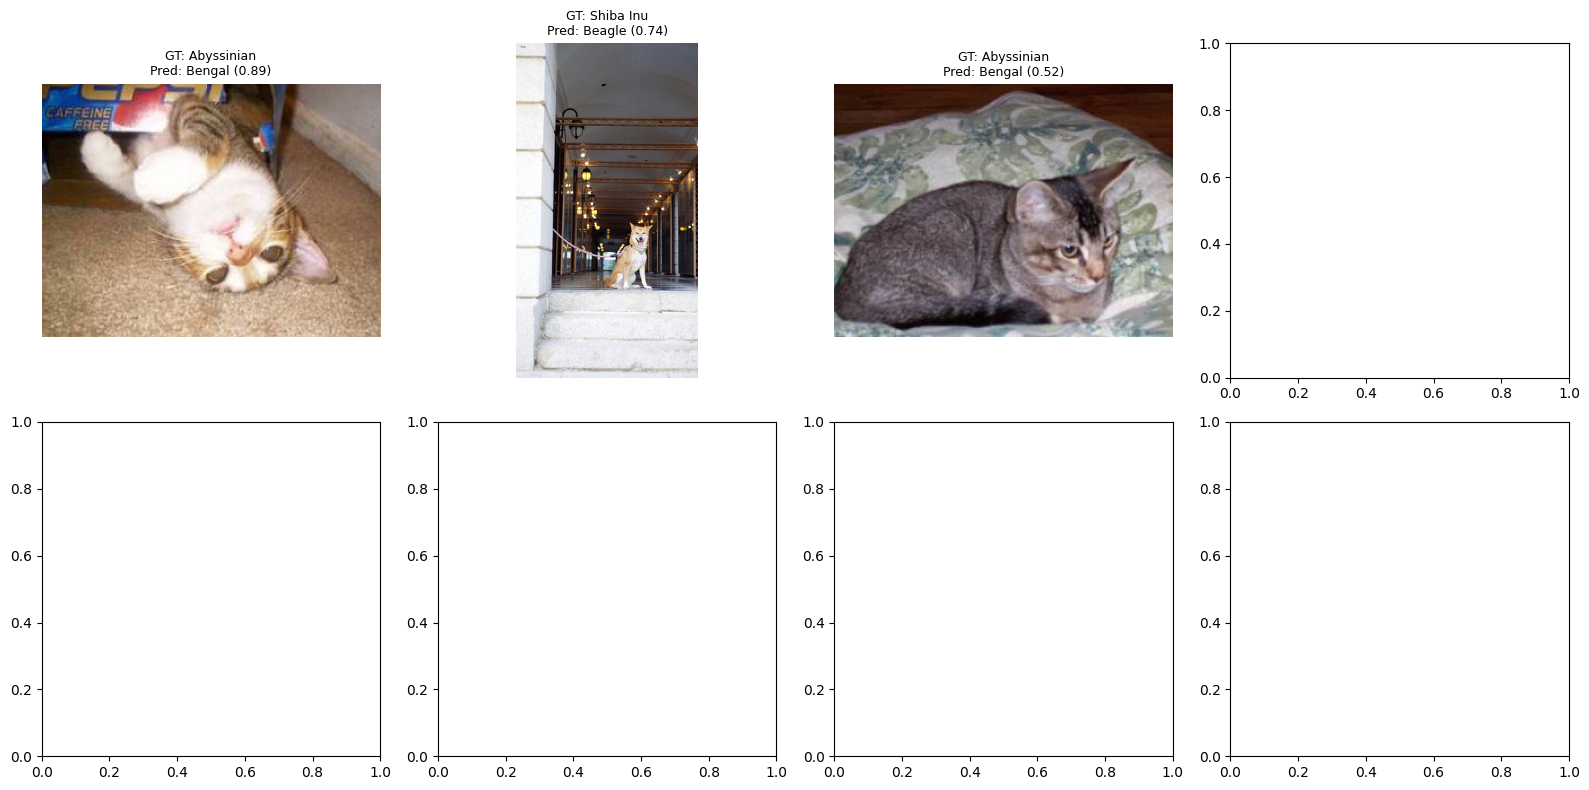

In [8]:
res = {"B1_scratch": r1, "B2_feature_extraction": r2, "B3_finetune_layer4": r3, "B4_finetune_no_aug": r4, "B5_efficientnet_b0": r5}
best = df.loc[df.test_macro_f1.idxmax(), "kondisi"]; print("Model terbaik:", best)
y, p, c = res[best]
wrong = np.where(y != p)[0]; print("Salah:", len(wrong), "dari", len(y))
sel = wrong[np.argsort(-c[wrong])][:8]   # 8 kesalahan dengan confidence tertinggi
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for a, i in zip(ax.ravel(), sel):
    a.imshow(Image.open(p_te[i]).convert("RGB")); a.axis("off")
    a.set_title(f"GT: {names[y[i]]}\nPred: {names[p[i]]} ({c[i]:.2f})", fontsize=9)
plt.tight_layout(); plt.savefig("failure_analysis.png", dpi=150); plt.show()

8 salah dari 297


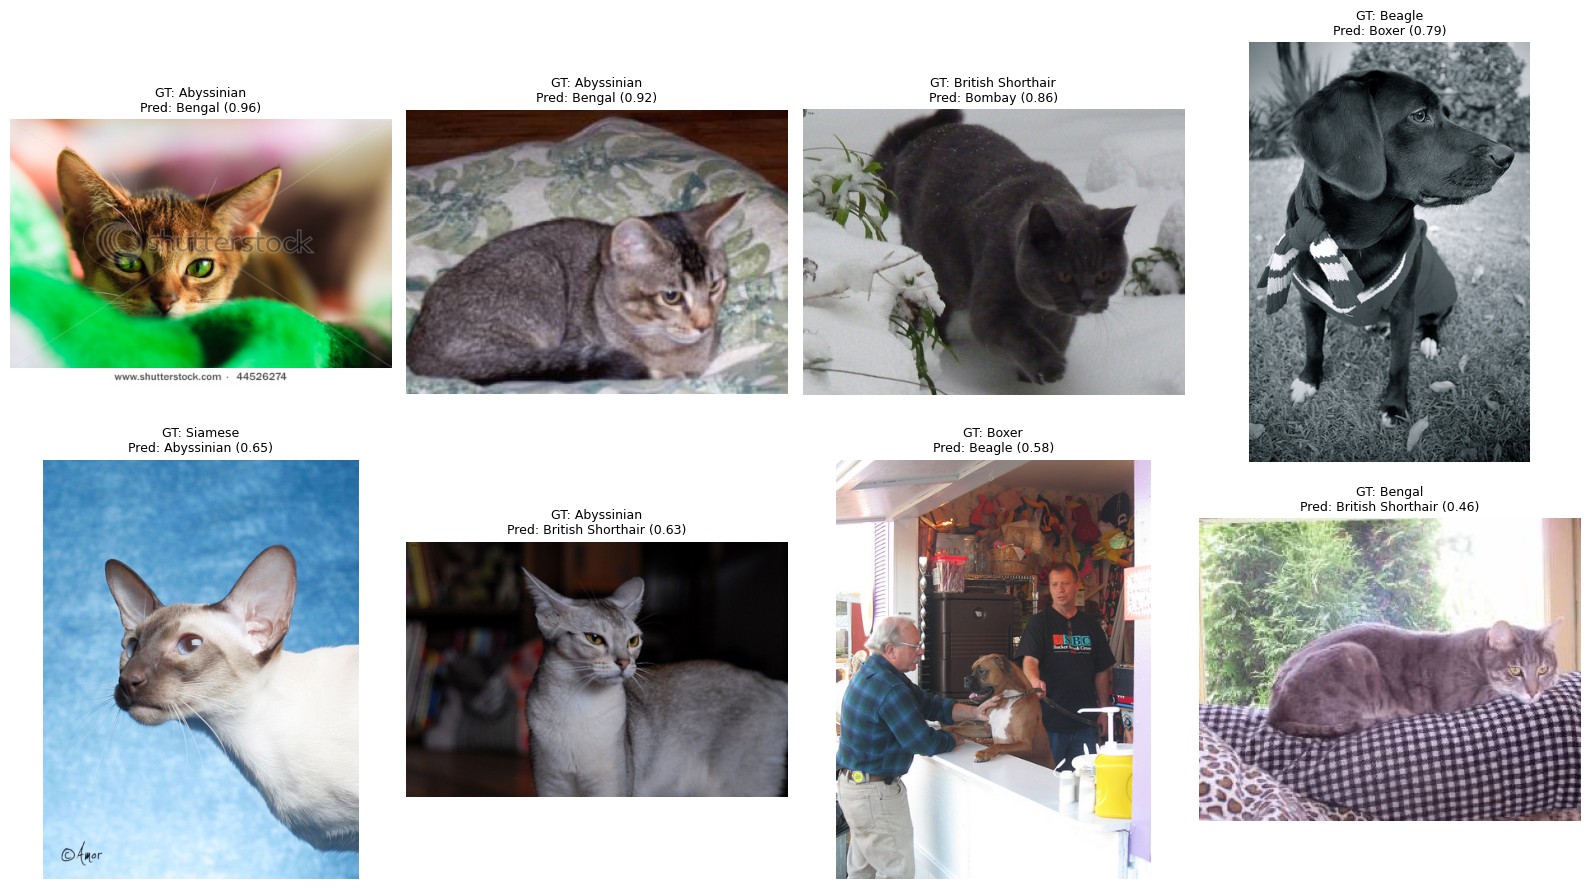

In [9]:
name = "B3_finetune_layer4"
y, p, c = r3
wrong = np.where(y != p)[0]
print(len(wrong), "salah dari", len(y))
sel = wrong[np.argsort(-c[wrong])][:8]

cols = 4; rows = (len(sel) + cols - 1) // cols
fig, ax = plt.subplots(rows, cols, figsize=(16, 4.5 * rows), squeeze=False)
for a in ax.ravel(): a.axis("off")
for a, i in zip(ax.ravel(), sel):
    a.imshow(Image.open(p_te[i]).convert("RGB"))
    a.set_title(f"GT: {names[y[i]]}\nPred: {names[p[i]]} ({c[i]:.2f})", fontsize=9)
plt.tight_layout(); plt.savefig("failure_analysis_B3.png", dpi=150); plt.show()

pd.DataFrame({"file": [str(p_te[i]) for i in wrong], "ground_truth": [names[y[i]] for i in wrong],
              "prediksi": [names[p[i]] for i in wrong], "confidence": c[wrong]}
            ).to_csv("misklasifikasi_B3.csv", index=False)